# 09 — Evaluación del análisis de sentimientos

## Objetivo y alcance

Evaluar las predicciones del modelo `cardiffnlp/twitter-xlm-roberta-base-sentiment` aplicado a **186 noticias** en el notebook 05, utilizando **60 noticias con etiquetas de referencia revisadas y confirmadas** (`negative`, `neutral`, `positive`).

Las predicciones originales se recuperan de `rss_sentiments` **exclusivamente mediante SELECT**. Este notebook no vuelve a ejecutar el modelo, no lo entrena y no modifica la base de datos.

**Diseño de muestra:** 60 noticias seleccionadas a partir de las 76 del experimento previo mediante muestreo estratificado por etiquetas sugeridas y semilla fija `20261123`. Es una evaluación acotada y no una muestra aleatoria representativa de las 186 noticias. Las etiquetas confirmadas corresponden a una revisión humana asistida; no hubo anotadores independientes.

El sentimiento corresponde al **tono del título y la descripción**, no a la valoración personal del acontecimiento. El modelo original utilizó ambos campos concatenados, con un límite de 512 tokens.


## 1. Bibliotecas y rutas


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import get_connection

CSV_NAME = "revision_sentimientos_60_definitivo.csv"
CSV_CANDIDATES = [
    Path.cwd() / CSV_NAME,
    PROJECT_ROOT / CSV_NAME,
    PROJECT_ROOT / "data" / CSV_NAME,
]
CSV_PATH = next((p for p in CSV_CANDIDATES if p.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError(
        f"No se encontró {CSV_NAME}. Ubicalo junto al notebook o en data/."
    )

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "evaluacion_sentimientos"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LABELS = ["negative", "neutral", "positive"]
MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
print("Archivo de referencia:", CSV_PATH)
print("Directorio de resultados:", OUTPUT_DIR)


Archivo de referencia: e:\Trabajo final UGR\communication-intelligence-assistant\notebooks\revision_sentimientos_60_definitivo.csv
Directorio de resultados: e:\Trabajo final UGR\communication-intelligence-assistant\outputs\evaluacion_sentimientos


## 2. Carga y validación de etiquetas de referencia

Solo se admite la columna `manual_sentiment` con revisión `confirmed`. No se utilizan etiquetas sugeridas ni predicciones del modelo para definir el conjunto de referencia.


In [2]:
reference = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
required = {"rss_news_id", "manual_sentiment", "review_status"}
assert required.issubset(reference.columns), required - set(reference.columns)
assert len(reference) == 60, "Se esperaban 60 noticias de referencia"
assert reference["rss_news_id"].notna().all()
assert reference["rss_news_id"].is_unique
assert reference["manual_sentiment"].isin(LABELS).all()
assert reference["review_status"].eq("confirmed").all()
assert reference["manual_sentiment"].notna().all()

reference["rss_news_id"] = reference["rss_news_id"].astype(int)
print("Etiquetas confirmadas:", len(reference))
print(reference["manual_sentiment"].value_counts().reindex(LABELS, fill_value=0))


Etiquetas confirmadas: 60
manual_sentiment
negative    12
neutral     31
positive    17
Name: count, dtype: int64


## 3. Recuperación de las predicciones originales (solo lectura)

Se consultan todas las filas del modelo en `rss_sentiments` para verificar el universo de 186 noticias. Se asocia `fk_rss_news_id` con `rss_news_id`; luego se toman las 60 seleccionadas para evaluar. Si la cobertura no coincide, la ejecución se detiene: no se crean predicciones faltantes.


In [3]:
query = """
    SELECT
        fk_rss_news_id AS rss_news_id,
        sentiment,
        positive_score,
        neutral_score,
        negative_score,
        model_name
    FROM rss_sentiments
    WHERE model_name = %s
    ORDER BY fk_rss_news_id;
"""
with get_connection() as connection:
    with connection.cursor() as cursor:
        cursor.execute(query, (MODEL_NAME,))
        columns = [column.name for column in cursor.description]
        predictions = pd.DataFrame(cursor.fetchall(), columns=columns)

assert len(predictions) == 186, (
    f"Se esperaban 186 predicciones originales; se encontraron {len(predictions)}"
)
assert predictions["rss_news_id"].is_unique
assert predictions["rss_news_id"].notna().all()
assert predictions["model_name"].eq(MODEL_NAME).all()
assert predictions["sentiment"].isin(LABELS).all()

score_columns = ["negative_score", "neutral_score", "positive_score"]
for col in score_columns:
    predictions[col] = pd.to_numeric(predictions[col], errors="raise")
assert predictions[score_columns].notna().all().all()
assert predictions[score_columns].ge(0).all().all()
assert predictions[score_columns].le(1).all().all()
assert (predictions[score_columns].sum(axis=1) - 1).abs().lt(0.01).all()

# El modelo 05 seleccionó la etiqueta con mayor puntuación.
assert predictions[score_columns].idxmax(axis=1).str.replace(
    "_score", "", regex=False
).eq(predictions["sentiment"]).all()

print("Noticias clasificadas en origen:", len(predictions))
print(predictions["sentiment"].value_counts().reindex(LABELS, fill_value=0))


Noticias clasificadas en origen: 186
sentiment
negative    33
neutral     95
positive    58
Name: count, dtype: int64


## 4. Unión y validación del conjunto evaluable
La unión debe mantener exactamente 60 pares referencia–predicción, sin duplicados ni datos faltantes.

In [4]:
evaluation_data = reference.merge(
    predictions,
    on="rss_news_id",
    how="left",
    validate="one_to_one",
)
assert len(evaluation_data) == 60
assert evaluation_data["sentiment"].notna().all(), "Hay IDs sin predicción"
assert evaluation_data["rss_news_id"].is_unique

y_true = evaluation_data["manual_sentiment"]
y_pred = evaluation_data["sentiment"]
print("Noticias evaluables:", len(evaluation_data))
print(pd.crosstab(y_true, y_pred, rownames=["Referencia"], colnames=["Modelo"]))


Noticias evaluables: 60
Modelo      negative  neutral  positive
Referencia                             
negative           7        4         1
neutral            4       17        10
positive           1       11         5


## 5. Métricas de clasificación

Se calcula Accuracy global y Precision, Recall y F1 para cada clase. Como la muestra no tiene clases perfectamente balanceadas, se informan **F1 macro** y **F1 ponderado**. Las métricas describen únicamente los 60 casos revisados, no el rendimiento poblacional de las 186 noticias.


In [5]:
print(classification_report(
    y_true, y_pred, labels=LABELS, zero_division=0, digits=4
))

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=LABELS, zero_division=0
)
per_class = pd.DataFrame({
    "Clase": LABELS,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Soporte": support,
})
summary = pd.DataFrame([{
    "Accuracy": accuracy_score(y_true, y_pred),
    "F1_macro": f1.mean(),
    "F1_weighted": (f1 * support).sum() / support.sum(),
    "Noticias_evaluadas": len(evaluation_data),
}])
print("Métricas por clase:")
display(per_class.round(4))
print("Resumen:")
display(summary.round(4))
per_class.to_csv(OUTPUT_DIR / "metricas_por_clase.csv", index=False, encoding="utf-8-sig")
summary.to_csv(OUTPUT_DIR / "resumen_metricas.csv", index=False, encoding="utf-8-sig")


              precision    recall  f1-score   support

    negative     0.5833    0.5833    0.5833        12
     neutral     0.5312    0.5484    0.5397        31
    positive     0.3125    0.2941    0.3030        17

    accuracy                         0.4833        60
   macro avg     0.4757    0.4753    0.4753        60
weighted avg     0.4797    0.4833    0.4814        60

Métricas por clase:


,Clase,Precision,Recall,F1,Soporte
0,negative,0.5833,0.5833,0.5833,12
1,neutral,0.5312,0.5484,0.5397,31
2,positive,0.3125,0.2941,0.3030,17


Resumen:


,Accuracy,F1_macro,F1_weighted,Noticias_evaluadas
0,0.4833,0.4753,0.4814,60


## 6. Matriz de confusión
Filas: etiqueta confirmada. Columnas: predicción del modelo.

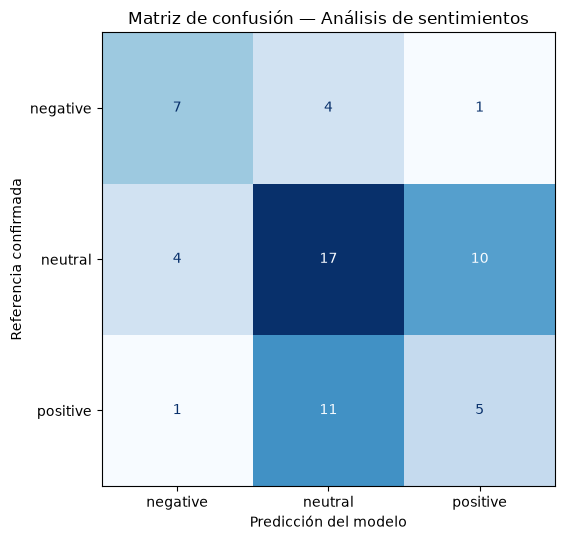

In [6]:
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
assert cm.sum() == 60
assert cm.trace() == int((y_true == y_pred).sum())

fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Matriz de confusión — Análisis de sentimientos")
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Referencia confirmada")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "matriz_confusion_sentimientos.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Análisis de errores
Se enumeran **todos** los desacuerdos para revisión cualitativa; no se modifica la referencia ni se ajusta el modelo a partir de ellos.

In [7]:
errors = evaluation_data.loc[
    y_true.ne(y_pred),
    ["rss_news_id", "title", "description", "manual_sentiment",
     "sentiment", "negative_score", "neutral_score", "positive_score"],
].copy()
errors = errors.sort_values("rss_news_id")
errors.to_csv(OUTPUT_DIR / "errores_clasificacion.csv", index=False, encoding="utf-8-sig")
print("Total de errores:", len(errors))
print("Aciertos:", int((y_true == y_pred).sum()))
display(errors)


Total de errores: 31
Aciertos: 29


,rss_news_id,title,description,manual_sentiment,sentiment,negative_score,neutral_score,positive_score
4,17,Los centros de datos de Estados Unidos ya cons...,Las instalaciones tecnológicas consumieron cer...,negative,neutral,0.054104,0.495056,0.450840
6,21,Amazon se une a Nvidia y tendrá dos millones d...,El gigante tecnológico desplegará los nuevos p...,neutral,positive,0.015233,0.349699,0.635067
7,23,Por qué Londres está frenando la llegada de lo...,El tráfico en la ciudad es uno de los factores...,neutral,negative,0.880992,0.103971,0.015037
9,27,IA en el quirófano: así fue la primera operaci...,"El algoritmo, entrenado con cientos de grabaci...",positive,neutral,0.110933,0.756091,0.132976
12,35,Solo 1 de cada 10 empresas conecta ventas y ma...,El modelo tradicional en productos de consumo ...,negative,neutral,0.079923,0.781738,0.138339
13,36,La puerta es el mejor lugar para guardar los l...,La ubicación dentro de la nevera afecta direct...,neutral,positive,0.029563,0.451143,0.519294
14,42,América Latina en el centro de la estrategia t...,La llegada de nuevos competidores con experien...,neutral,positive,0.029010,0.336844,0.634146
17,49,"Así funciona ProPILOT, un asistente de IA que ...",Cámaras y sensores de los autos trabajan en co...,positive,neutral,0.023079,0.614037,0.362885
19,57,Elon Musk construirá en Luisiana un segundo St...,La nueva instalación incluirá producción de co...,neutral,positive,0.017678,0.428589,0.553733
23,80,Bill Gates alerta al mundo: “la transición a l...,El empresario advierte que debemos prepararnos...,negative,neutral,0.403810,0.422224,0.173966


## Conclusiones de la evaluación del análisis de sentimientos

La evaluación del modelo `cardiffnlp/twitter-xlm-roberta-base-sentiment` se realizó sobre una muestra de 60 noticias con etiquetas de referencia revisadas y confirmadas manualmente, seleccionadas a partir del corpus procesado de 186 noticias.

### Resultados cuantitativos

El modelo obtuvo una **Accuracy de 48,33 %**, equivalente a 29 clasificaciones correctas y 31 incorrectas. El **F1-score macro fue de 0,4753**, mientras que el F1-score ponderado alcanzó 0,4814, lo que evidencia un rendimiento limitado y relativamente similar entre ambas métricas agregadas.

El análisis por clase mostró diferencias en el desempeño:

- **Negativo:** obtuvo el mayor F1-score (0,5833), con 7 de 12 noticias correctamente clasificadas.
- **Neutral:** alcanzó un F1-score de 0,5397, identificando correctamente 17 de 31 noticias.
- **Positivo:** presentó el menor rendimiento, con un F1-score de 0,3030 y solamente 5 de 17 noticias correctamente identificadas.

### Interpretación de la matriz de confusión

La matriz de confusión permitió identificar que la principal dificultad del modelo se encuentra en la distinción entre sentimientos positivos y neutrales.

De las 31 clasificaciones incorrectas, **21 corresponden a confusiones entre estas dos categorías**: 11 noticias positivas fueron clasificadas como neutrales y 10 noticias neutrales fueron clasificadas como positivas.

También se observaron dificultades para reconocer algunas noticias negativas, de las cuales cuatro fueron clasificadas como neutrales y una como positiva.

Estos resultados sugieren que el modelo presenta limitaciones para diferenciar el tono descriptivo de las noticias de las valoraciones favorables, especialmente cuando los textos informan sobre avances, desarrollos o aplicaciones tecnológicas.

### Consideraciones y limitaciones

El modelo evaluado fue desarrollado originalmente para analizar sentimientos en publicaciones de redes sociales. Su aplicación sobre noticias periodísticas representa un contexto lingüístico diferente, lo que podría contribuir a las dificultades observadas.

Asimismo, el análisis de sentimientos presenta un componente interpretativo, particularmente en textos informativos que describen acontecimientos sin expresar una valoración emocional explícita.

Como referencia adicional, un clasificador que asignara siempre la clase mayoritaria (*neutral*) alcanzaría una Accuracy de 51,67 % sobre esta muestra, superior al resultado obtenido por el modelo. Por lo tanto, el rendimiento observado no demuestra una mejora frente a esta línea base en términos de exactitud.

La evaluación se limita a 60 noticias seleccionadas de un conjunto experimental previo, por lo que sus resultados no deben extrapolarse directamente a las 186 noticias del corpus completo ni a otros conjuntos de datos.

### Conclusión general

La evaluación permitió cuantificar el comportamiento del componente de análisis de sentimientos e identificar sus principales limitaciones. Aunque el modelo logra reconocer correctamente una parte de las noticias negativas y neutrales, presenta dificultades importantes en la identificación del sentimiento positivo.

En consecuencia, **el componente se encuentra funcionalmente implementado, pero su rendimiento predictivo resulta limitado en la muestra evaluada**.

Estos resultados constituyen evidencia empírica para el análisis del prototipo y permiten identificar oportunidades de mejora, como la utilización de modelos especializados en textos periodísticos, la adaptación al dominio y la ampliación del conjunto de evaluación.



